Using device: cuda
Training autoencoder...


Epoch 1/50: 100%|██████████| 32/32 [00:13<00:00,  2.41it/s]


Epoch [1/50], Loss: 0.740825


Epoch 2/50: 100%|██████████| 32/32 [00:11<00:00,  2.79it/s]


Epoch [2/50], Loss: 0.492595


Epoch 3/50: 100%|██████████| 32/32 [00:11<00:00,  2.84it/s]


... (95 outputs left out)

100%|██████████| 32/32 [00:10<00:00,  3.05it/s]


Extracted features shape: (1000, 15360)

Performing K-means clustering...
Adjusted Rand Index (ARI): 0.1242
Normalized Mutual Information (NMI): 0.2377

Visualizing with t-SNE dimensionality reduction...

Visualizing cluster centroids...

Cluster to true label mapping: {0: 0, 1: 3, 2: 0, 3: 2, 4: 4}

Clustering Classification Report:
              precision    recall  f1-score   support

        five       0.53      0.71      0.61       200
        four       0.00      0.00      0.00       200
         one       0.38      0.34      0.36       200
       three       0.36      0.67      0.47       200
         two       0.46      0.42      0.44       200

    accuracy                           0.43      1000
   macro avg       0.35      0.43      0.37      1000
weighted avg       0.35      0.43      0.37      1000


Visualizing autoencoder reconstructions...


d:\Python\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
d:\Python\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
d:\Python\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Unsupervised learning completed! All results saved in 'unsupervised_results' directory


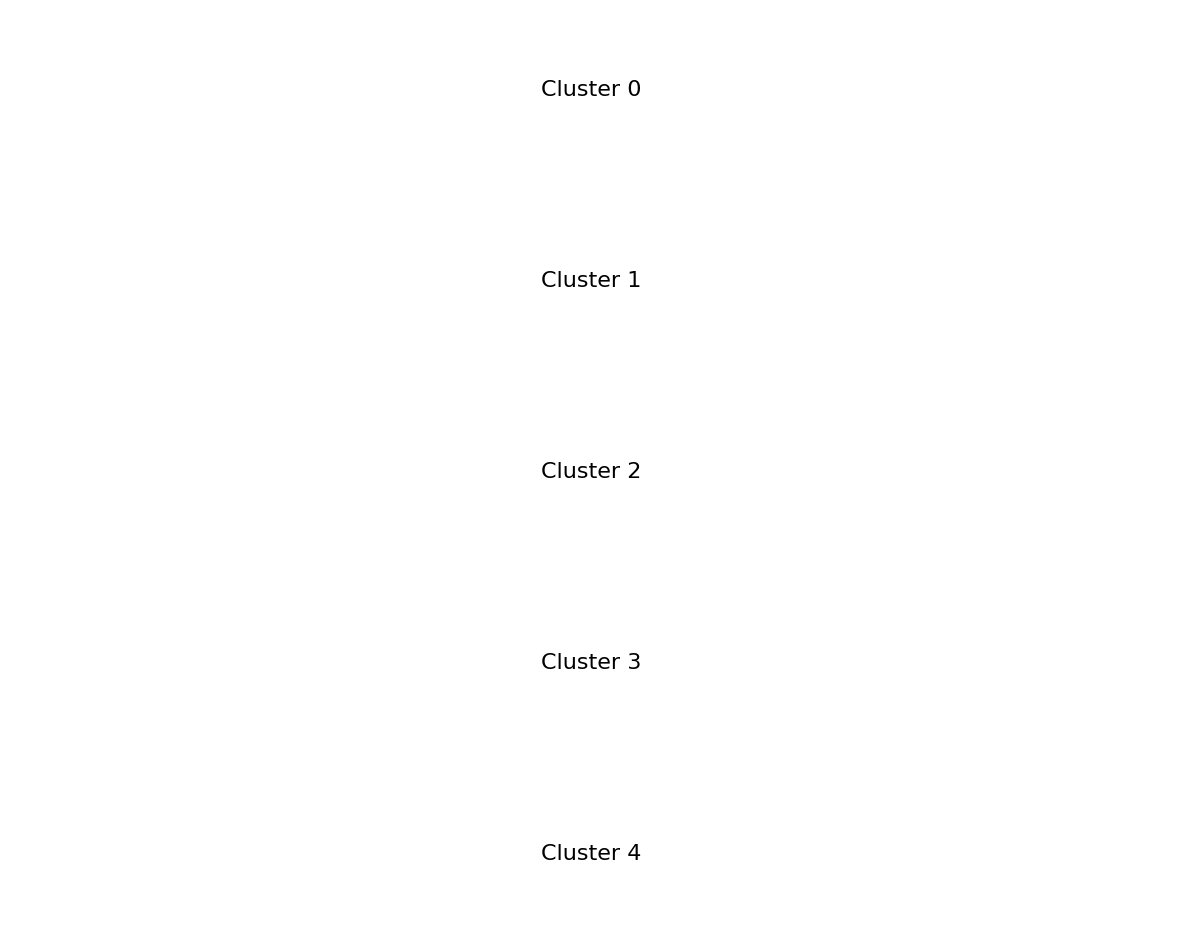

In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import transforms, datasets
from torch.utils.data import DataLoader
from sklearn.cluster import KMeans
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt
import numpy as np
import os
from PIL import Image
import seaborn as sns
from tqdm import tqdm

# Set random seed for reproducibility
torch.manual_seed(42)
np.random.seed(42)

# Check CUDA availability
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

# Create results directory
os.makedirs('unsupervised_results', exist_ok=True)

# Preprocessing for 1600x350 size images
transform = transforms.Compose([
    transforms.Resize((350, 1600)),
    transforms.CenterCrop((320, 1536)),
    transforms.Resize((80, 384)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# Load dataset
dataset = datasets.ImageFolder(r'D:\STUDY\internship\code_internship\dataset\images', transform=transform)
dataloader = DataLoader(dataset, batch_size=32, shuffle=False, num_workers=4)

# Define convolutional autoencoder
class ConvAutoencoder(nn.Module):
    def __init__(self):
        super(ConvAutoencoder, self).__init__()
        
        # Encoder
        self.encoder = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=(3, 7), padding=(1, 3)),
            nn.ReLU(),
            nn.MaxPool2d((2, 4)),  # Output: [32, 40, 96]
            
            nn.Conv2d(32, 64, kernel_size=(3, 7), padding=(1, 3)),
            nn.ReLU(),
            nn.MaxPool2d((2, 4)),  # Output: [64, 20, 24]
            
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d((2, 2)),  # Output: [128, 10, 12]
        )
        
        # Decoder
        self.decoder = nn.Sequential(
            nn.ConvTranspose2d(128, 64, kernel_size=3, stride=2, padding=1, output_padding=1),
            nn.ReLU(),
            
            nn.ConvTranspose2d(64, 32, kernel_size=(3, 7), stride=(2, 4), padding=(1, 3), output_padding=(1, 3)),
            nn.ReLU(),
            
            nn.ConvTranspose2d(32, 3, kernel_size=(3, 7), stride=(2, 4), padding=(1, 3), output_padding=(1, 3)),
            nn.Sigmoid()  # Output values between 0-1
        )
    
    def forward(self, x):
        x = self.encoder(x)
        x = self.decoder(x)
        return x
    
    def encode(self, x):
        with torch.no_grad():
            return self.encoder(x)

# Initialize model and optimizer
model = ConvAutoencoder().to(device)
criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

# Train autoencoder
num_epochs = 50
train_losses = []

print("Training autoencoder...")
for epoch in range(num_epochs):
    running_loss = 0.0
    for images, _ in tqdm(dataloader, desc=f"Epoch {epoch+1}/{num_epochs}"):
        images = images.to(device)
        
        # Forward pass
        outputs = model(images)
        loss = criterion(outputs, images)
        
        # Backward pass and optimize
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        
        running_loss += loss.item() * images.size(0)
    
    epoch_loss = running_loss / len(dataloader.dataset)
    train_losses.append(epoch_loss)
    print(f"Epoch [{epoch+1}/{num_epochs}], Loss: {epoch_loss:.6f}")

# Save autoencoder model
torch.save(model.state_dict(), 'unsupervised_results/autoencoder.pth')

# Plot training loss curve
plt.figure(figsize=(10, 6))
plt.plot(train_losses)
plt.title('Autoencoder Training Loss')
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.grid(True)
plt.savefig('unsupervised_results/autoencoder_loss.png', dpi=300)
plt.close()

# Extract latent features of all images
print("\nExtracting image features...")
features = []
image_paths = [item[0] for item in dataset.imgs]
true_labels = [item[1] for item in dataset.imgs]

model.eval()
with torch.no_grad():
    for images, _ in tqdm(dataloader):
        images = images.to(device)
        batch_features = model.encode(images)
        features.append(batch_features.cpu().numpy())

# Flatten features and convert to numpy array
features = np.vstack(features)
features = features.reshape(features.shape[0], -1)  # Flatten features for each sample
print(f"Extracted features shape: {features.shape}")

# Perform K-means clustering
print("\nPerforming K-means clustering...")
kmeans = KMeans(n_clusters=5, random_state=42, n_init=10)
cluster_labels = kmeans.fit_predict(features)

# Save clustering results
np.save('unsupervised_results/cluster_labels.npy', cluster_labels)
np.save('unsupervised_results/true_labels.npy', true_labels)

# Evaluate clustering results
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

ari = adjusted_rand_score(true_labels, cluster_labels)
nmi = normalized_mutual_info_score(true_labels, cluster_labels)
print(f"Adjusted Rand Index (ARI): {ari:.4f}")
print(f"Normalized Mutual Information (NMI): {nmi:.4f}")

# Visualize clustering results with t-SNE
print("\nVisualizing with t-SNE dimensionality reduction...")
tsne = TSNE(n_components=2, random_state=42, perplexity=30)
features_2d = tsne.fit_transform(features)

plt.figure(figsize=(12, 10))
sns.scatterplot(x=features_2d[:, 0], y=features_2d[:, 1], 
                hue=cluster_labels, palette='viridis', 
                s=50, alpha=0.8, edgecolor='none')
plt.title('t-SNE Visualization of Clustering Results')
plt.savefig('unsupervised_results/tsne_clusters.png', dpi=300)
plt.close()

# Plot comparison of true labels vs cluster labels
plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
sns.scatterplot(x=features_2d[:, 0], y=features_2d[:, 1], 
                hue=true_labels, palette='viridis', 
                s=50, alpha=0.8, edgecolor='none')
plt.title('True Label Distribution')

plt.subplot(1, 2, 2)
sns.scatterplot(x=features_2d[:, 0], y=features_2d[:, 1], 
                hue=cluster_labels, palette='viridis', 
                s=50, alpha=0.8, edgecolor='none')
plt.title('Cluster Label Distribution')

plt.tight_layout()
plt.savefig('unsupervised_results/true_vs_cluster.png', dpi=300)
plt.close()

# Visualize cluster centroids
print("\nVisualizing cluster centroids...")
cluster_centers = kmeans.cluster_centers_

# Find representative images for each cluster (closest to centroid)
representative_indices = []
for i in range(5):
    # Calculate distance from all samples to cluster center
    distances = np.linalg.norm(features - cluster_centers[i], axis=1)
    # Find the 10 closest samples
    closest_indices = np.argsort(distances)[:10]
    representative_indices.append(closest_indices)

# Visualize clustering results
plt.figure(figsize=(15, 12))
for cluster_idx in range(5):
    # Display cluster label
    plt.subplot(5, 1, cluster_idx+1)
    plt.text(0.5, 0.5, f'Cluster {cluster_idx}', 
             fontsize=16, ha='center', va='center')
    plt.axis('off')
    
    # Display representative images for this cluster
    plt.figure(figsize=(15, 3))
    plt.suptitle(f'Cluster {cluster_idx} - Representative Images', fontsize=16)
    
    for j, img_idx in enumerate(representative_indices[cluster_idx][:5]):
        img_path = image_paths[img_idx]
        img = Image.open(img_path)
        
        plt.subplot(1, 5, j+1)
        plt.imshow(img)
        plt.title(f'Image {img_idx}')
        plt.axis('off')
    
    plt.tight_layout()
    plt.savefig(f'unsupervised_results/cluster_{cluster_idx}_examples.png', dpi=300)
    plt.close()

# Generate clustering report
from sklearn.metrics import confusion_matrix, classification_report

# Create mapping from cluster to true label (majority voting)
cluster_to_label = {}
for cluster in range(5):
    # Get all true labels in this cluster
    true_in_cluster = [true_labels[i] for i, c in enumerate(cluster_labels) if c == cluster]
    # Find the most common true label
    most_common = max(set(true_in_cluster), key=true_in_cluster.count)
    cluster_to_label[cluster] = most_common

print("\nCluster to true label mapping:", cluster_to_label)

# Map cluster labels to true labels
predicted_labels = [cluster_to_label[c] for c in cluster_labels]

# Calculate confusion matrix
cm = confusion_matrix(true_labels, predicted_labels)

# Plot confusion matrix
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=dataset.classes, 
            yticklabels=dataset.classes)
plt.title('Clustering Results Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.savefig('unsupervised_results/confusion_matrix.png', dpi=300)
plt.close()

# Print classification report
print("\nClustering Classification Report:")
print(classification_report(true_labels, predicted_labels, target_names=dataset.classes))

# Visualize reconstruction results
print("\nVisualizing autoencoder reconstructions...")
test_images = next(iter(dataloader))[0][:5]  # Take first 5 images
test_images = test_images.to(device)

model.eval()
with torch.no_grad():
    reconstructed = model(test_images)

# Denormalization function
def denormalize(tensor):
    mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1).to(device)
    std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1).to(device)
    return tensor * std + mean

# Visualize original and reconstructed images
plt.figure(figsize=(15, 6))
for i in range(5):
    # Original image
    plt.subplot(2, 5, i+1)
    img = denormalize(test_images[i]).cpu().permute(1, 2, 0).numpy()
    plt.imshow(np.clip(img, 0, 1))
    plt.title(f'Original {i}')
    plt.axis('off')
    
    # Reconstructed image
    plt.subplot(2, 5, i+6)
    rec_img = denormalize(reconstructed[i]).cpu().permute(1, 2, 0).numpy()
    plt.imshow(np.clip(rec_img, 0, 1))
    plt.title(f'Reconstructed {i}')
    plt.axis('off')

plt.tight_layout()
plt.savefig('unsupervised_results/reconstruction_examples.png', dpi=300)
plt.close()

print("\nUnsupervised learning completed! All results saved in 'unsupervised_results' directory")